In [1]:
import pandas as pd

In [3]:
df = pd.read_excel('/content/Online Retail.xlsx')

In [4]:
df.shape


(541909, 8)

In [5]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [6]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
df.columns.tolist()

['InvoiceNo',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'UnitPrice',
 'CustomerID',
 'Country']

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [9]:
missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

print(pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
}))

             Missing Values  Missing Percentage
InvoiceNo                 0            0.000000
StockCode                 0            0.000000
Description            1454            0.268311
Quantity                  0            0.000000
InvoiceDate               0            0.000000
UnitPrice                 0            0.000000
CustomerID           135080           24.926694
Country                   0            0.000000


In [10]:
df.duplicated().sum()

np.int64(5268)

In [11]:
print("Original rows:", len(df))

print("Duplicate rows:", df.duplicated().sum())

print("Rows after removing duplicates:", len(df.drop_duplicates()))

Original rows: 541909
Duplicate rows: 5268
Rows after removing duplicates: 536641


In [12]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (536641, 8)


In [13]:
df[df['Description'].isnull()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [14]:
missing_desc = df[df['Description'].isnull()]

print("Total missing descriptions:", len(missing_desc))
print("Zero unit price:", (missing_desc['UnitPrice'] == 0).sum())
print("Non-zero unit price:", (missing_desc['UnitPrice'] != 0).sum())
print("Negative quantity:", (missing_desc['Quantity'] < 0).sum())

Total missing descriptions: 1454
Zero unit price: 1454
Non-zero unit price: 0
Negative quantity: 862


In [15]:
df = df.dropna(subset=['Description'])

print("Dataset shape:", df.shape)
print("Missing descriptions:", df['Description'].isnull().sum())

Dataset shape: (535187, 8)
Missing descriptions: 0


In [16]:
negative_qty = df[df['Quantity'] < 0]

print("Negative quantity records:", len(negative_qty))
print("Total negative quantity:", negative_qty['Quantity'].sum())

Negative quantity records: 9725
Total negative quantity: -436361


In [17]:
df['InvoiceNo'].astype(str).str.startswith('C').sum()

np.int64(9251)

In [18]:
negative_mask = df['Quantity'] < 0

cancel_mask = df['InvoiceNo'].astype(str).str.startswith('C')

print("Negative quantity AND cancellation:",
      (negative_mask & cancel_mask).sum())

print("Negative quantity WITHOUT cancellation:",
      (negative_mask & ~cancel_mask).sum())

print("Cancellation WITHOUT negative quantity:",
      (cancel_mask & ~negative_mask).sum())

Negative quantity AND cancellation: 9251
Negative quantity WITHOUT cancellation: 474
Cancellation WITHOUT negative quantity: 0


In [19]:
non_cancel_returns = df[
    (df['Quantity'] < 0) &
    (~df['InvoiceNo'].astype(str).str.startswith('C'))
]

non_cancel_returns.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
7313,537032,21275,?,-30,2010-12-03 16:50:00,0.0,NaN,United Kingdom
13217,537425,84968F,check,-20,2010-12-06 15:35:00,0.0,NaN,United Kingdom
13218,537426,84968E,check,-35,2010-12-06 15:36:00,0.0,NaN,United Kingdom
13264,537432,35833G,damages,-43,2010-12-06 16:10:00,0.0,NaN,United Kingdom
21338,538072,22423,faulty,-13,2010-12-09 14:10:00,0.0,NaN,United Kingdom
21518,538090,20956,?,-723,2010-12-09 14:48:00,0.0,NaN,United Kingdom
22296,538161,46000S,Dotcom sales,-100,2010-12-09 17:25:00,0.0,NaN,United Kingdom
22297,538162,46000M,Dotcom sales,-100,2010-12-09 17:25:00,0.0,NaN,United Kingdom
42564,540010,22501,reverse 21/5/10 adjustment,-100,2011-01-04 11:13:00,0.0,NaN,United Kingdom
42566,540012,22502,reverse 21/5/10 adjustment,-100,2011-01-04 11:14:00,0.0,NaN,United Kingdom


In [20]:
print("Total records:", len(non_cancel_returns))

print("Zero unit price:",
      (non_cancel_returns['UnitPrice'] == 0).sum())

print("Non-zero unit price:",
      (non_cancel_returns['UnitPrice'] != 0).sum())

print("\nDescriptions:")
print(non_cancel_returns['Description'].value_counts().head(15))

Total records: 474
Zero unit price: 474
Non-zero unit price: 0

Descriptions:
Description
check                     120
damages                    45
damaged                    42
?                          41
sold as set on dotcom      20
Damaged                    14
thrown away                 9
Unsaleable, destroyed.      9
??                          7
damages?                    5
ebay                        5
wet damaged                 5
smashed                     4
CHECK                       3
missing                     3
Name: count, dtype: int64


In [21]:
print("Zero or negative prices:",
      (df['UnitPrice'] <= 0).sum())

print("Zero prices:",
      (df['UnitPrice'] == 0).sum())

print("Negative prices:",
      (df['UnitPrice'] < 0).sum())

Zero or negative prices: 1058
Zero prices: 1056
Negative prices: 2


In [22]:
df[df['UnitPrice'] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [23]:
zero_price = df[df['UnitPrice'] == 0]

print("Total zero-price records:", len(zero_price))

print("\nTop descriptions:")
print(zero_price['Description'].value_counts().head(20))

Total zero-price records: 1056

Top descriptions:
Description
check                             159
?                                  47
damages                            45
damaged                            43
found                              25
sold as set on dotcom              20
adjustment                         16
Damaged                            14
Unsaleable, destroyed.              9
FRENCH BLUE METAL DOOR SIGN 1       9
thrown away                         9
amazon                              8
FRENCH BLUE METAL DOOR SIGN 8       8
Found                               8
FRENCH BLUE METAL DOOR SIGN 3       7
??                                  7
Amazon                              7
FRENCH BLUE METAL DOOR SIGN 4       7
FRENCH BLUE METAL DOOR SIGN No      7
OWL DOORSTOP                        7
Name: count, dtype: int64


In [24]:
df = df[df['UnitPrice'] > 0].copy()

print("Dataset shape:", df.shape)

Dataset shape: (534129, 8)


In [25]:
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')].copy()

print("Dataset shape:", df.shape)

Dataset shape: (524878, 8)


In [26]:
df['Revenue'] = df['Quantity'] * df['UnitPrice']

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [27]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNegative quantities:", (df['Quantity'] < 0).sum())

print("\nZero or negative prices:", (df['UnitPrice'] <= 0).sum())

print("\nTotal Revenue:", df['Revenue'].sum())

Dataset shape: (524878, 9)

Missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
dtype: int64

Duplicate rows: 0

Negative quantities: 0

Zero or negative prices: 0

Total Revenue: 10642110.804000001


In [28]:
df.to_excel('Ecommerce_Cleaned.xlsx', index=False)

In [29]:
from google.colab import files
files.download('Ecommerce_Cleaned.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
print("Total Revenue:", df['Revenue'].sum())

print("Total Quantity Sold:", df['Quantity'].sum())

print("Total Transactions:", df['InvoiceNo'].nunique())

print("Total Products:", df['StockCode'].nunique())

print("Total Customers:", df['CustomerID'].nunique())

print("Total Countries:", df['Country'].nunique())

Total Revenue: 10642110.804000001
Total Quantity Sold: 5572420
Total Transactions: 19960
Total Products: 3922
Total Customers: 4338
Total Countries: 38


In [31]:
print("Total Revenue (£):", round(df['Revenue'].sum(), 2))
print("Total Quantity Sold:", df['Quantity'].sum())
print("Total Transactions:", df['InvoiceNo'].nunique())
print("Total Products:", df['StockCode'].nunique())
print("Total Customers:", df['CustomerID'].nunique())
print("Total Countries:", df['Country'].nunique())

Total Revenue (£): 10642110.8
Total Quantity Sold: 5572420
Total Transactions: 19960
Total Products: 3922
Total Customers: 4338
Total Countries: 38


In [32]:
monthly_sales = df.groupby(
    df['InvoiceDate'].dt.to_period('M')
)['Revenue'].sum()

monthly_sales

,Revenue
InvoiceDate,
2010-12,821452.730
2011-01,689811.610
2011-02,522545.560
2011-03,716215.260
2011-04,536968.491
2011-05,769296.610
2011-06,760547.010
2011-07,718076.121
2011-08,757841.380


In [33]:
print("Highest Sales Month:")
print(monthly_sales.idxmax(), "-> £", round(monthly_sales.max(), 2))

print("\nLowest Sales Month:")
print(monthly_sales.idxmin(), "-> £", round(monthly_sales.min(), 2))

Highest Sales Month:
2011-11 -> £ 1503866.78

Lowest Sales Month:
2011-02 -> £ 522545.56


In [34]:
top_products = (
    df.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

,Revenue
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78101.88
Manual,77752.82


In [35]:
country_sales = (
    df.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_sales

,Revenue
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340


In [36]:
customer_sales = (
    df.dropna(subset=['CustomerID'])
    .groupby('CustomerID')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

customer_sales

,Revenue
CustomerID,
14646.0,280206.02
18102.0,259657.30
17450.0,194390.79
16446.0,168472.50
14911.0,143711.17
12415.0,124914.53
14156.0,117210.08
17511.0,91062.38
16029.0,80850.84


In [37]:
customer_orders = (
    df.dropna(subset=['CustomerID'])
    .groupby('CustomerID')['InvoiceNo']
    .nunique()
)

repeat_customers = customer_orders[customer_orders > 1]

print("Total Identified Customers:", len(customer_orders))
print("Repeat Customers:", len(repeat_customers))
print("One-time Customers:", (customer_orders == 1).sum())

Total Identified Customers: 4338
Repeat Customers: 2845
One-time Customers: 1493


In [38]:
import pandas as pd

reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = (
    df.dropna(subset=['CustomerID'])
    .groupby('CustomerID')
    .agg(
        Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
        Frequency=('InvoiceNo', 'nunique'),
        Monetary=('Revenue', 'sum')
    )
)

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [39]:
rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    4,
    labels=[4, 3, 2, 1]
).astype(int)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
CustomerID,,,,,,
12346.0,326,1,77183.60,1,1,4
12347.0,2,7,4310.00,4,4,4
12348.0,75,4,1797.24,2,3,4
12349.0,19,1,1757.55,3,1,4
12350.0,310,1,334.40,1,1,2


In [40]:
def segment_customer(row):
    if row['R_Score'] >= 3 and row['F_Score'] >= 3:
        return 'Loyal Customers'
    elif row['R_Score'] == 4 and row['F_Score'] <= 2:
        return 'New Customers'
    elif row['R_Score'] <= 2 and row['F_Score'] >= 3:
        return 'At Risk'
    elif row['R_Score'] <= 2 and row['F_Score'] <= 2:
        return 'Lost Customers'
    else:
        return 'Regular Customers'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)

print(rfm['Segment'].value_counts())

Segment
Lost Customers       1514
Loyal Customers      1514
At Risk               655
Regular Customers     434
New Customers         221
Name: count, dtype: int64


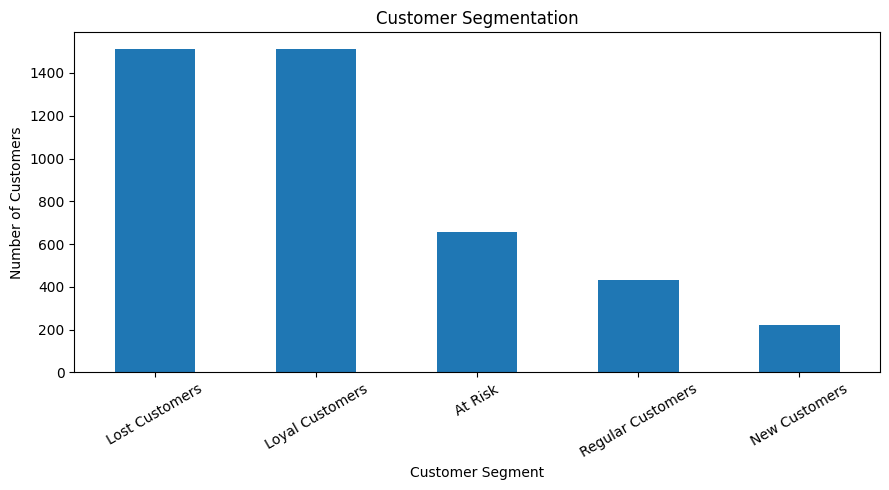

In [41]:
import matplotlib.pyplot as plt

rfm['Segment'].value_counts().plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Customer Segmentation')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [43]:
df.to_excel('Ecommerce_Cleaned1.xlsx', index=False)

rfm.to_csv('Customer_RFM_Analysis.csv')

print("Both files exported successfully!")

Both files exported successfully!


In [44]:
from google.colab import files

files.download('Ecommerce_Cleaned1.xlsx')
files.download('Customer_RFM_Analysis.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>